<a href="https://colab.research.google.com/github/dzikrilazizhakim/Semester-5/blob/main/PRAKTIKUM_PCD_DZIKRIL_AZIZ_HAKIM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import shutil

import numpy as np
import imageio.v3 as iio
import matplotlib.pyplot as plt

MEMBUAT GAMBAR

Saving image_singa.jpg to image_singa.jpg
Ukuran citra (tinggi, lebar, kanal): (527, 612, 3)


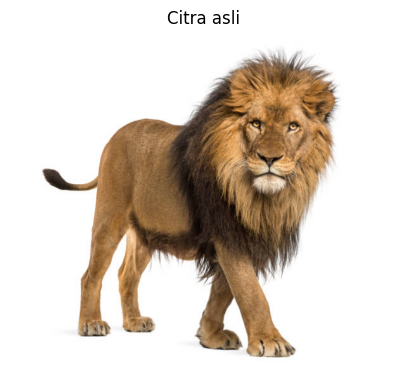

In [2]:
try:
    from google.colab import files  # hanya tersedia di Google Colab
    uploaded = files.upload()
    IMG_PATH = next(iter(uploaded))
except ImportError:
    IMG_PATH = "gambar.jpg"

def perkecil_jika_besar(citra, sisi_maks=1000):
    """Perkecil citra (nearest neighbor) jika sisi terpanjangnya > sisi_maks.
    Supaya rotasi/zoom tidak memakai RAM berlebihan di Colab (foto HP bisa 4000px+)."""
    tinggi, lebar = citra.shape[:2]
    faktor = max(tinggi, lebar) / sisi_maks
    if faktor <= 1:
        return citra
    baris = np.minimum((np.arange(int(tinggi / faktor)) * faktor).astype(int), tinggi - 1)
    kolom = np.minimum((np.arange(int(lebar / faktor)) * faktor).astype(int), lebar - 1)
    return citra[baris[:, None], kolom[None, :]]


image = iio.imread(IMG_PATH)
if image.ndim == 2:                      # grayscale -> 3 kanal (RGB)
    image = np.stack([image] * 3, axis=-1)
image = image[..., :3].astype(np.uint8)  # buang kanal alpha jika ada
image = perkecil_jika_besar(image)       # opsional: batasi ukuran agar proses ringan

print("Ukuran citra (tinggi, lebar, kanal):", image.shape)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Citra asli")
plt.axis("off")
plt.show()

FUNGSI BANTU UNTUK MENAMPILKAN DAN MENYIMPAN HASIL

In [3]:
OUT_DIR = "hasil"
os.makedirs(OUT_DIR, exist_ok=True)


def tampilkan_perbandingan(sebelum, sesudah, judul_sebelum, judul_sesudah):
    """Menampilkan dua citra berdampingan."""
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(sebelum)
    ax[0].set_title(judul_sebelum)
    ax[0].axis("off")
    ax[1].imshow(sesudah)
    ax[1].set_title(judul_sesudah)
    ax[1].axis("off")
    plt.show()


def simpan(nama_file, citra):
    """Menyimpan citra ke folder hasil/ (untuk lampiran GitHub / laporan)."""
    iio.imwrite(os.path.join(OUT_DIR, nama_file), citra)

1a. TRANSLASI CITRA

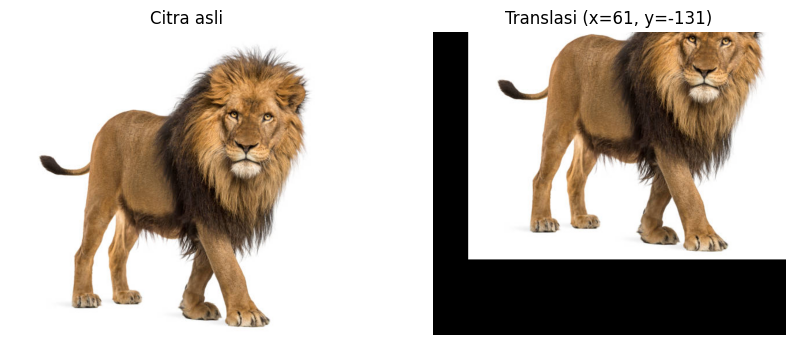

In [4]:
def translasi(citra, shift_x, shift_y):
    tinggi, lebar = citra.shape[:2]
    hasil = np.zeros_like(citra)

    # Jika geser sejauh seluruh ukuran citra, hasilnya seluruhnya hitam
    if abs(shift_x) >= lebar or abs(shift_y) >= tinggi:
        return hasil

    # Area sumber (bagian citra asli yang tetap terlihat)
    sumber_y0, sumber_y1 = max(0, -shift_y), min(tinggi, tinggi - shift_y)
    sumber_x0, sumber_x1 = max(0, -shift_x), min(lebar, lebar - shift_x)

    # Area tujuan (posisi baru di kanvas)
    tujuan_y0, tujuan_y1 = max(0, shift_y), min(tinggi, tinggi + shift_y)
    tujuan_x0, tujuan_x1 = max(0, shift_x), min(lebar, lebar + shift_x)

    hasil[tujuan_y0:tujuan_y1, tujuan_x0:tujuan_x1] = \
        citra[sumber_y0:sumber_y1, sumber_x0:sumber_x1]
    return hasil


# Geser 10% lebar ke kanan dan 25% tinggi ke atas (menyesuaikan ukuran gambar Anda)
shift_x = image.shape[1] // 10
shift_y = -(image.shape[0] // 4)

hasil_1a = translasi(image, shift_x=shift_x, shift_y=shift_y)
tampilkan_perbandingan(image, hasil_1a, "Citra asli",
                       f"Translasi (x={shift_x}, y={shift_y})")
simpan("1a_translasi.png", hasil_1a)

1b. MIRRORING

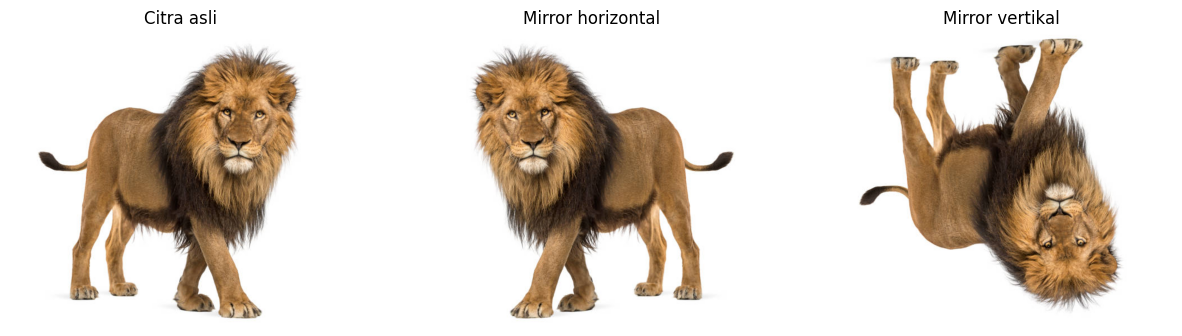

In [5]:
def mirror_horizontal(citra):
    return citra[:, ::-1].copy()


def mirror_vertikal(citra):
    return citra[::-1, :].copy()


hasil_1b_h = mirror_horizontal(image)
hasil_1b_v = mirror_vertikal(image)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (citra, judul) in zip(ax, [(image, "Citra asli"),
                                  (hasil_1b_h, "Mirror horizontal"),
                                  (hasil_1b_v, "Mirror vertikal")]):
    a.imshow(citra)
    a.set_title(judul)
    a.axis("off")
plt.show()

simpan("1b_mirror_horizontal.png", hasil_1b_h)
simpan("1b_mirror_vertikal.png", hasil_1b_v)

1c. ROTASI CITRA PUSAT ROTASI DI TENGAH CITRA

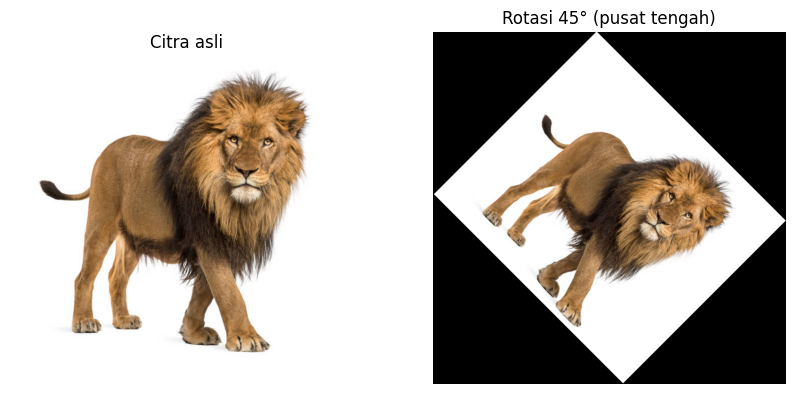

In [6]:
def rotasi(citra, derajat):
    tinggi, lebar = citra.shape[:2]
    theta = np.radians(derajat)
    cos_t, sin_t = np.cos(theta), np.sin(theta)

    # Kanvas output berbentuk persegi dengan sisi = diagonal citra
    sisi = int(np.ceil(np.round(np.sqrt(tinggi ** 2 + lebar ** 2), 6)))
    hasil = np.zeros((sisi, sisi) + citra.shape[2:], dtype=citra.dtype)

    pusat_out = sisi / 2
    pusat_in_x, pusat_in_y = lebar / 2, tinggi / 2

    # Koordinat setiap piksel output, relatif terhadap pusat output
    Y, X = np.mgrid[0:sisi, 0:sisi]
    dx = X - pusat_out
    dy = Y - pusat_out

    # Invers rotasi -> koordinat piksel asal
    src_x = np.round(cos_t * dx + sin_t * dy + pusat_in_x).astype(int)
    src_y = np.round(-sin_t * dx + cos_t * dy + pusat_in_y).astype(int)

    valid = (src_x >= 0) & (src_x < lebar) & (src_y >= 0) & (src_y < tinggi)
    hasil[valid] = citra[src_y[valid], src_x[valid]]
    return hasil


hasil_1c = rotasi(image, 45)
tampilkan_perbandingan(image, hasil_1c, "Citra asli", "Rotasi 45° (pusat tengah)")
simpan("1c_rotasi_pusat_tengah.png", hasil_1c)

1d. ZOOMING PERBESAR

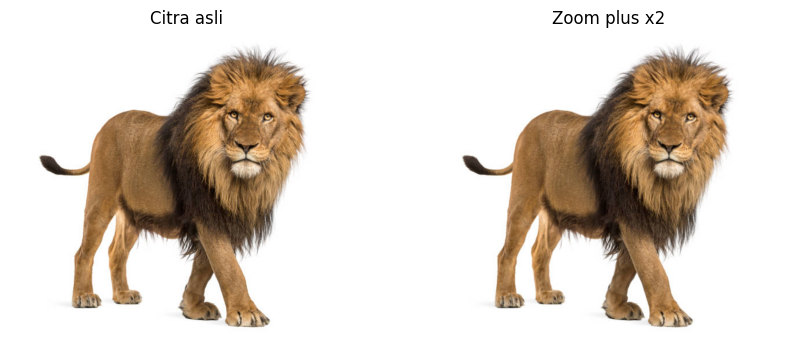

In [7]:
def zoom_plus(citra, faktor):
    if faktor <= 0:
        raise ValueError("faktor harus > 0")
    tinggi, lebar = citra.shape[:2]
    tinggi_baru, lebar_baru = int(tinggi * faktor), int(lebar * faktor)

    baris_asal = np.minimum((np.arange(tinggi_baru) / faktor).astype(int), tinggi - 1)
    kolom_asal = np.minimum((np.arange(lebar_baru) / faktor).astype(int), lebar - 1)
    return citra[baris_asal[:, None], kolom_asal[None, :]]


hasil_1d = zoom_plus(image, 2.0)
tampilkan_perbandingan(image, hasil_1d, "Citra asli", "Zoom plus x2")
simpan("1d_zoom_plus.png", hasil_1d)

2a. MIRRORING VERTIKAL DAN HORIZONTAL SECARA BERSAMAAN

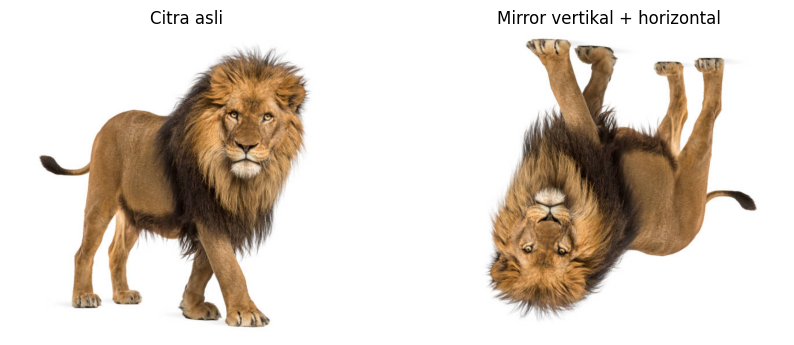

In [8]:
def mirror_bersamaan(citra):
    return citra[::-1, ::-1].copy()


hasil_2a = mirror_bersamaan(image)
tampilkan_perbandingan(image, hasil_2a, "Citra asli", "Mirror vertikal + horizontal")
simpan("2a_mirror_bersamaan.png", hasil_2a)

2b. ROTASI CITRA DENGAN PIVOT DI (0.0) POJOK KIRI ATAS

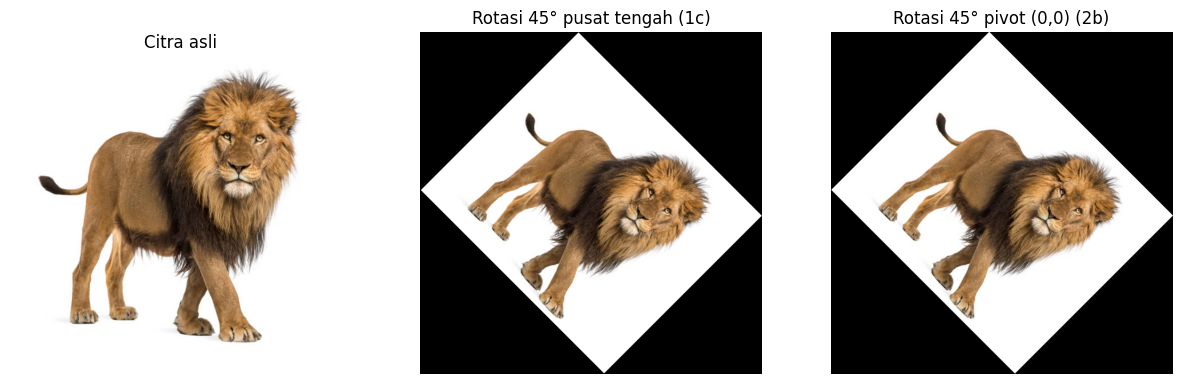

In [9]:
def rotasi_pivot_pojok(citra, derajat):
    tinggi, lebar = citra.shape[:2]
    theta = np.radians(derajat)
    cos_t, sin_t = np.cos(theta), np.sin(theta)

    # Posisi 4 pojok citra setelah diputar terhadap (0,0)
    pojok_x = np.array([0, lebar, 0, lebar], dtype=float)
    pojok_y = np.array([0, 0, tinggi, tinggi], dtype=float)
    rot_x = cos_t * pojok_x - sin_t * pojok_y
    rot_y = sin_t * pojok_x + cos_t * pojok_y

    min_x, min_y = rot_x.min(), rot_y.min()
    # round() dulu agar error floating-point (mis. cos 90° ≈ 6e-17) tidak menambah 1 piksel
    lebar_out = int(np.ceil(np.round(rot_x.max() - min_x, 6)))
    tinggi_out = int(np.ceil(np.round(rot_y.max() - min_y, 6)))
    hasil = np.zeros((tinggi_out, lebar_out) + citra.shape[2:], dtype=citra.dtype)

    # Setiap piksel output -> koordinat di ruang rotasi -> invers rotasi ke piksel asal
    Y, X = np.mgrid[0:tinggi_out, 0:lebar_out]
    xr = X + min_x
    yr = Y + min_y
    src_x = np.round(cos_t * xr + sin_t * yr).astype(int)
    src_y = np.round(-sin_t * xr + cos_t * yr).astype(int)

    valid = (src_x >= 0) & (src_x < lebar) & (src_y >= 0) & (src_y < tinggi)
    hasil[valid] = citra[src_y[valid], src_x[valid]]
    return hasil


hasil_2b = rotasi_pivot_pojok(image, 45)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (citra, judul) in zip(ax, [(image, "Citra asli"),
                                  (hasil_1c, "Rotasi 45° pusat tengah (1c)"),
                                  (hasil_2b, "Rotasi 45° pivot (0,0) (2b)")]):
    a.imshow(citra)
    a.set_title(judul)
    a.axis("off")
plt.show()
simpan("2b_rotasi_pivot_pojok.png", hasil_2b)

2c. ZOOM MINUS (PERKECIL GAMBAR)

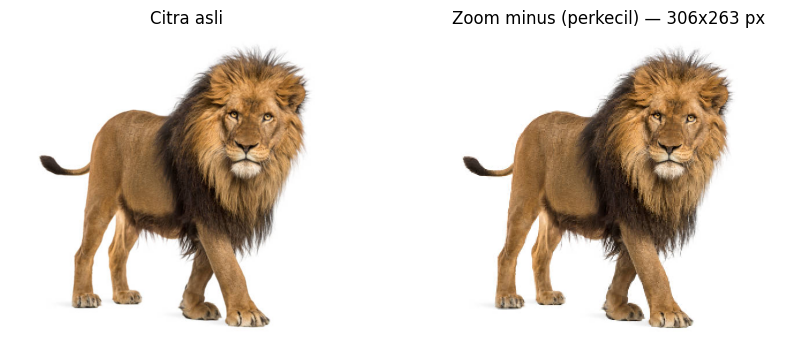

In [10]:
def zoom_minus(citra, faktor):
    if faktor <= 0:
        raise ValueError("faktor harus > 0")
    tinggi, lebar = citra.shape[:2]
    tinggi_baru = max(1, int(tinggi / faktor))
    lebar_baru = max(1, int(lebar / faktor))

    baris_asal = np.minimum((np.arange(tinggi_baru) * faktor).astype(int), tinggi - 1)
    kolom_asal = np.minimum((np.arange(lebar_baru) * faktor).astype(int), lebar - 1)
    return citra[baris_asal[:, None], kolom_asal[None, :]]


hasil_2c = zoom_minus(image, 2.0)
tampilkan_perbandingan(image, hasil_2c, "Citra asli",
                       f"Zoom minus (perkecil) — {hasil_2c.shape[1]}x{hasil_2c.shape[0]} px")
simpan("2c_zoom_minus.png", hasil_2c)

MENGUNDUH SEMUA HASIL (OPSIONAL, DI GOOGLE COLAB)

In [11]:
shutil.make_archive("hasil", "zip", OUT_DIR)
print("Isi folder hasil:", sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files as colab_files
    colab_files.download("hasil.zip")
except ImportError:
    print("Berjalan di luar Colab: file hasil ada di", os.path.abspath("hasil.zip"))

Isi folder hasil: ['1a_translasi.png', '1b_mirror_horizontal.png', '1b_mirror_vertikal.png', '1c_rotasi_pusat_tengah.png', '1d_zoom_plus.png', '2a_mirror_bersamaan.png', '2b_rotasi_pivot_pojok.png', '2c_zoom_minus.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>